Install Packages

In [19]:
%pip -q install rasterio

Connect to Drive

In [20]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Locate the exported images

In [21]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio

PROJECT_DIR = Path("/content/drive/MyDrive")
DATA_DIR = PROJECT_DIR / "Akagera_HLS_Pilot"

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Folder not found: {DATA_DIR}\n"
        "Move Akagera_HLS_Pilot directly into MyDrive."
    )

FILENAMES = {
    "dry_2024": "Akagera_dry_candidate_2024.tif",
    "dry_2025": "Akagera_dry_candidate_2025.tif",
    "wet_2025": "Akagera_wet_candidate_2025.tif",
}

paths = {
    name: DATA_DIR / filename
    for name, filename in FILENAMES.items()
}

missing = [
    path.name for path in paths.values()
    if not path.is_file()
]

if missing:
    print("Files currently present:")
    for path in sorted(DATA_DIR.iterdir()):
        print(" ", path.name)

    raise FileNotFoundError(f"Missing exports: {missing}")

print("All three Akagera imagery exports found.")

All three Akagera imagery exports found.


Load reflectance and valid-pixel masks

In [22]:
BAND_NAMES = ["blue", "green", "red", "nir", "swir1", "swir2"]

def load_hls_export(path):
    with rasterio.open(path) as src:
        if src.count != 9:
            raise ValueError(
                f"{path.name}: expected 9 bands, found {src.count}"
            )

        # First six bands: surface reflectance.
        masked = src.read(
            indexes=[1, 2, 3, 4, 5, 6],
            masked=True
        ).astype("float32")

        reflectance = masked.filled(np.nan)

        # Band 9: valid-pixel flag from the GEE script.
        quality = src.read(9, masked=True).filled(0)

        valid = (
            (quality == 1)
            & ~np.ma.getmaskarray(masked).any(axis=0)
            & np.isfinite(reflectance).all(axis=0)
        )

        reflectance[:, ~valid] = np.nan

        return {
            "image": reflectance,
            "valid": valid,
            "crs": src.crs,
            "transform": src.transform,
            "shape": (src.height, src.width),
            "path": str(path),
        }

data = {
    name: load_hls_export(path)
    for name, path in paths.items()
}

summary = pd.DataFrame([
    {
        "sample": name,
        "image_shape": item["image"].shape,
        "valid_percent": round(100 * item["valid"].mean(), 2),
        "crs": str(item["crs"]),
    }
    for name, item in data.items()
])

display(summary)

,sample,image_shape,valid_percent,crs
0,dry_2024,"(6, 224, 225)",98.61,EPSG:32736
1,dry_2025,"(6, 224, 225)",99.22,EPSG:32736
2,wet_2025,"(6, 224, 225)",99.05,EPSG:32736


Display the images side by side

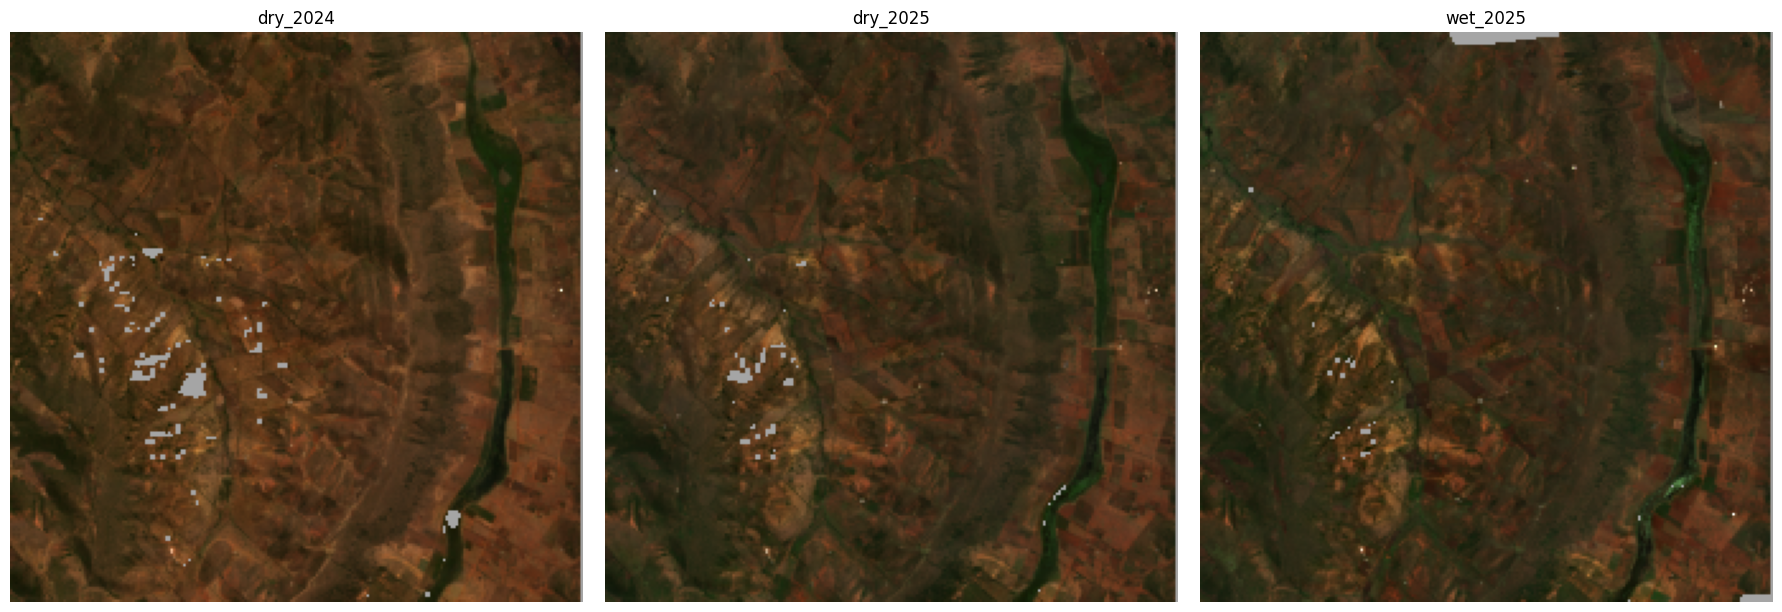

In [23]:
def rgb_preview(item):
    # Stored order: blue, green, red, NIR, SWIR1, SWIR2.
    rgb = item["image"][[2, 1, 0]].transpose(1, 2, 0)

    # Common reflectance display range.
    rgb = np.clip((rgb - 0.01) / (0.30 - 0.01), 0, 1)
    rgb = np.nan_to_num(rgb, nan=0.0)

    # Grey indicates invalid pixels.
    rgb[~item["valid"]] = [0.65, 0.65, 0.65]
    return rgb

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (name, item) in zip(axes, data.items()):
    ax.imshow(rgb_preview(item))
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

Format all images same size 244

In [24]:
TARGET_SIZE = 224

for name, item in data.items():
    height, width = item["image"].shape[-2:]

    if height < TARGET_SIZE or width < TARGET_SIZE:
        raise ValueError(f"{name}: image is smaller than 224 × 224")

    # Keep the upper-left 224 × 224 pixels consistently.
    item["image"] = item["image"][:, :TARGET_SIZE, :TARGET_SIZE]
    item["valid"] = item["valid"][:TARGET_SIZE, :TARGET_SIZE]
    item["shape"] = (TARGET_SIZE, TARGET_SIZE)

    # The geographic transform remains unchanged because
    # we remove pixels only from the bottom/right edges.

print("All images and masks now have dimensions 224 × 224.")

All images and masks now have dimensions 224 × 224.


Construct the first candidate image pair

In [25]:
before = data["dry_2024"]
after = data["dry_2025"]

# A pixel must be valid on BOTH dates.
pair_valid = before["valid"] & after["valid"]

# Shape: time × bands × height × width.
image_pair = np.stack([
    before["image"],
    after["image"],
], axis=0)

image_pair[:, :, ~pair_valid] = np.nan

print("Pair shape:", image_pair.shape)
print(f"Joint valid coverage: {100 * pair_valid.mean():.2f}%")
print("Reference change label: not yet available.")

Pair shape: (2, 6, 224, 224)
Joint valid coverage: 98.90%
Reference change label: not yet available.


Amazonia inspection

,system:index,crs,date,grid_xmin,grid_ymax,image_id,joint_valid_fraction,label_asset,label_status,label_transition,...,requested_tile,role,sample_id,selection_method,shortlist_size,sun_azimuth,sun_zenith,tile,valid_fraction,.geo
0,0,EPSG:32721,2021-06-30,698910,9528750,NASA/HLS/HLSS30/v002/T21MXR_20210630T140059,1,projects/mapbiomas-public/assets/amazon/lulc/c...,provisional_unverified,2021_to_2022,...,21MXR,before,amazon_001,fixed_tile_cloud_shortlist_then_patch_valid_fr...,8,40.899723,36.767325,21MXR,1,"{""type"":""MultiPoint"",""coordinates"":[]}"
1,1,EPSG:32721,2023-07-25,698910,9528750,NASA/HLS/HLSS30/v002/T21MXR_20230725T135711,1,projects/mapbiomas-public/assets/amazon/lulc/c...,provisional_unverified,2021_to_2022,...,21MXR,after,amazon_001,fixed_tile_cloud_shortlist_then_patch_valid_fr...,8,46.059566,34.868739,21MXR,1,"{""type"":""MultiPoint"",""coordinates"":[]}"


All four Amazonia rasters share the same grid.
Actual dimensions: (224, 224)
Joint imagery coverage: 100.00%
Pixels with usable imagery and labels: 32,650
  Provisional stable forest: 29,331
  Provisional conversion:   3,319
Conversion share among eligible pixels: 10.17%


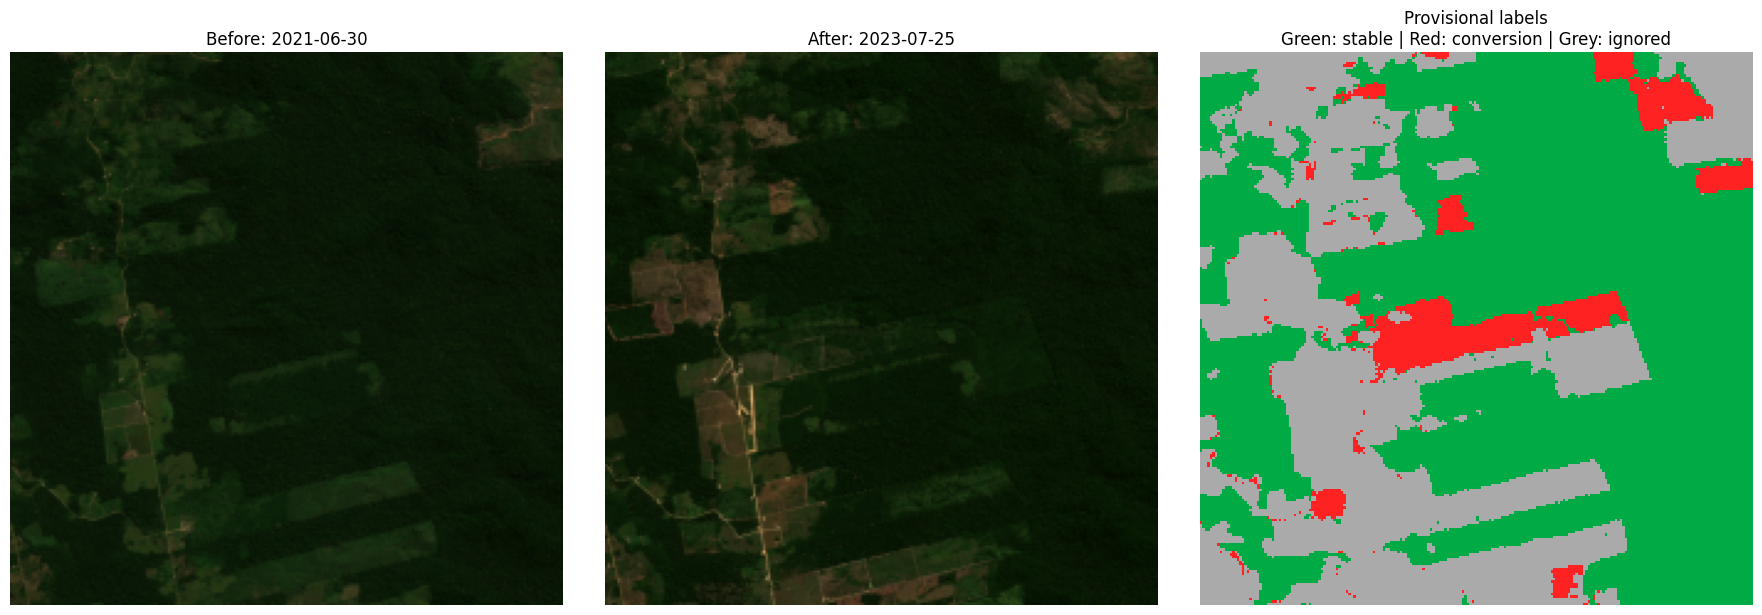

Amazonia sample loaded. Labels remain provisional.


In [26]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import rasterio

# ---------- 1. Locate exports ----------

PROJECT_DIR = Path("/content/drive/MyDrive")
SOURCE_DIR = PROJECT_DIR / "Amazonia_Source_Pilot"
SAMPLE_ID = "amazon_001"

if not SOURCE_DIR.is_dir():
    raise FileNotFoundError(
        f"Folder not found: {SOURCE_DIR}\n"
        "Move Amazonia_Source_Pilot directly into MyDrive."
    )

source_paths = {
    "before": SOURCE_DIR / f"{SAMPLE_ID}_before_2021.tif",
    "after": SOURCE_DIR / f"{SAMPLE_ID}_after_2023.tif",
    "labels": SOURCE_DIR / f"{SAMPLE_ID}_provisional_labels.tif",
    "joint_valid": SOURCE_DIR / f"{SAMPLE_ID}_joint_valid.tif",
    "metadata": SOURCE_DIR / f"{SAMPLE_ID}_metadata.csv",
}

missing = [
    path.name for path in source_paths.values()
    if not path.is_file()
]

if missing:
    print("Files currently present:")
    for path in sorted(SOURCE_DIR.iterdir()):
        print(" ", path.name)

    raise FileNotFoundError(f"Missing Amazonia exports: {missing}")

# ---------- 2. Read rasters ----------

def read_source_raster(path):
    with rasterio.open(path) as src:
        return {
            "array": src.read(),
            "masks": src.read_masks(),
            "crs": src.crs,
            "transform": src.transform,
            "shape": (src.height, src.width),
            "count": src.count,
        }

source_rasters = {
    name: read_source_raster(source_paths[name])
    for name in ["before", "after", "labels", "joint_valid"]
}

source_metadata = pd.read_csv(source_paths["metadata"])
display(source_metadata)

# ---------- 3. Check alignment ----------

assert source_rasters["before"]["count"] == 9, (
    "Before image: expected 9 bands."
)
assert source_rasters["after"]["count"] == 9, (
    "After image: expected 9 bands."
)
assert source_rasters["labels"]["count"] == 1, (
    "Labels: expected 1 band."
)
assert source_rasters["joint_valid"]["count"] == 1, (
    "Joint mask: expected 1 band."
)

source_reference = source_rasters["before"]

for name, item in source_rasters.items():
    assert item["shape"] == source_reference["shape"], (
        f"{name}: dimensions differ."
    )
    assert item["crs"] == source_reference["crs"], (
        f"{name}: coordinate system differs."
    )
    assert item["transform"].almost_equals(
        source_reference["transform"]
    ), f"{name}: pixel grid differs."

print("All four Amazonia rasters share the same grid.")
print("Actual dimensions:", source_reference["shape"])

# ---------- 4. Extract imagery and masks ----------

source_before = source_rasters["before"]["array"][:6].astype("float32")
source_after = source_rasters["after"]["array"][:6].astype("float32")

def source_imagery_valid(item):
    reflectance = item["array"][:6]

    return (
        (item["array"][8] == 1)
        & (item["masks"][:6] > 0).all(axis=0)
        & np.isfinite(reflectance).all(axis=0)
    )

source_before_valid = source_imagery_valid(source_rasters["before"])
source_after_valid = source_imagery_valid(source_rasters["after"])

source_joint_export = (
    (source_rasters["joint_valid"]["array"][0] == 1)
    & (source_rasters["joint_valid"]["masks"][0] > 0)
)

source_joint_valid = source_before_valid & source_after_valid

if not np.array_equal(source_joint_export, source_joint_valid):
    raise ValueError(
        "The exported joint mask differs from the image-derived mask. "
        "Check that all files come from the same export run."
    )

source_labels = source_rasters["labels"]["array"][0].astype("int16")

unexpected = set(np.unique(source_labels).tolist()) - {0, 1, 255}
if unexpected:
    raise ValueError(f"Unexpected label values: {unexpected}")

source_label_valid = (
    np.isin(source_labels, [0, 1])
    & (source_rasters["labels"]["masks"][0] > 0)
)

source_supervised_valid = source_joint_valid & source_label_valid

source_before[:, ~source_before_valid] = np.nan
source_after[:, ~source_after_valid] = np.nan

# ---------- 5. Report usable pixels ----------

stable_count = int(
    ((source_labels == 0) & source_supervised_valid).sum()
)
change_count = int(
    ((source_labels == 1) & source_supervised_valid).sum()
)
eligible_count = int(source_supervised_valid.sum())

print(f"Joint imagery coverage: {100 * source_joint_valid.mean():.2f}%")
print(f"Pixels with usable imagery and labels: {eligible_count:,}")
print(f"  Provisional stable forest: {stable_count:,}")
print(f"  Provisional conversion:   {change_count:,}")

if eligible_count:
    print(
        "Conversion share among eligible pixels: "
        f"{100 * change_count / eligible_count:.2f}%"
    )

if stable_count == 0 or change_count == 0:
    print("CHECK: The patch does not contain both usable label classes.")

# ---------- 6. Visual inspection ----------

def source_rgb_preview(image, valid):
    rgb = image[[2, 1, 0]].transpose(1, 2, 0)
    rgb = np.clip((rgb - 0.01) / (0.30 - 0.01), 0, 1)
    rgb = np.nan_to_num(rgb, nan=0.0)
    rgb[~valid] = [0.65, 0.65, 0.65]
    return rgb

label_display = np.full(source_labels.shape, 2, dtype="uint8")
label_display[source_supervised_valid & (source_labels == 0)] = 0
label_display[source_supervised_valid & (source_labels == 1)] = 1

label_colors = ListedColormap(["#00aa44", "#ff2222", "#aaaaaa"])

before_date = source_metadata.loc[
    source_metadata["role"] == "before", "date"
].iloc[0]

after_date = source_metadata.loc[
    source_metadata["role"] == "after", "date"
].iloc[0]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(source_rgb_preview(source_before, source_before_valid))
axes[0].set_title(f"Before: {before_date}")

axes[1].imshow(source_rgb_preview(source_after, source_after_valid))
axes[1].set_title(f"After: {after_date}")

axes[2].imshow(
    label_display,
    cmap=label_colors,
    vmin=0,
    vmax=2,
    interpolation="nearest",
)
axes[2].set_title(
    "Provisional labels\n"
    "Green: stable | Red: conversion | Grey: ignored"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# ---------- 7. Preserve the sample ----------

amazon_sample = {
    "before": source_before,
    "after": source_after,
    "labels": source_labels,
    "joint_valid": source_joint_valid,
    "supervised_valid": source_supervised_valid,
    "metadata": source_metadata,
    "crs": source_reference["crs"],
    "transform": source_reference["transform"],
}

print("Amazonia sample loaded. Labels remain provisional.")

In [27]:
# ============================================================
# STAGE 2 — SAVE CURRENT DATA EVIDENCE AND EVALUATION DESIGN
# Run after mounting Google Drive.
#
# Reads:
#   MyDrive/Amazonia_Source_Pilot/
#
# Writes:
#   MyDrive/MLEO_STAGE2_SUBMISSION/
#
# No model training or protected-test evaluation occurs here.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import rasterio

# ---------- 1. Paths ----------

DRIVE = Path("/content/drive/MyDrive")
DATA_DIR = DRIVE / "Amazonia_Source_Pilot"
ROOT = DRIVE / "MLEO_STAGE2_SUBMISSION"

for folder in [
    "data",
    "checks",
    "design",
    "results",
    "figures",
    "reports",
    "reproducibility",
]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

SAMPLE_ID = "amazon_001"

files = {
    "before": DATA_DIR / f"{SAMPLE_ID}_before_2021.tif",
    "after": DATA_DIR / f"{SAMPLE_ID}_after_2023.tif",
    "labels": DATA_DIR / f"{SAMPLE_ID}_provisional_labels.tif",
    "joint_valid": DATA_DIR / f"{SAMPLE_ID}_joint_valid.tif",
    "metadata": DATA_DIR / f"{SAMPLE_ID}_metadata.csv",
}

missing = [str(path) for path in files.values() if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Required exports are missing:\n" + "\n".join(missing)
    )

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def write_json(path, value):
    path.write_text(
        json.dumps(value, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )

# ---------- 2. Read files and repeat quality checks ----------

def read_raster(path):
    with rasterio.open(path) as src:
        return {
            "array": src.read(),
            "masks": src.read_masks(),
            "crs": src.crs,
            "transform": src.transform,
            "shape": (src.height, src.width),
            "count": src.count,
            "nodata": src.nodata,
            "bounds": tuple(src.bounds),
        }

rasters = {
    key: read_raster(files[key])
    for key in ["before", "after", "labels", "joint_valid"]
}

metadata = pd.read_csv(files["metadata"])
reference = rasters["before"]

checks = {}

checks["expected_band_counts"] = (
    rasters["before"]["count"] == 9
    and rasters["after"]["count"] == 9
    and rasters["labels"]["count"] == 1
    and rasters["joint_valid"]["count"] == 1
)

checks["matching_shapes"] = all(
    item["shape"] == reference["shape"]
    for item in rasters.values()
)

checks["matching_crs"] = all(
    item["crs"] == reference["crs"]
    for item in rasters.values()
)

checks["matching_transforms"] = all(
    item["transform"].almost_equals(reference["transform"])
    for item in rasters.values()
)

checks["expected_patch_dimensions"] = reference["shape"] == (224, 224)

checks["expected_pixel_size"] = (
    np.isclose(reference["transform"].a, 30)
    and np.isclose(reference["transform"].e, -30)
    and np.isclose(reference["transform"].b, 0)
    and np.isclose(reference["transform"].d, 0)
)

failed = [name for name, passed in checks.items() if not passed]
if failed:
    write_json(ROOT / "checks" / "failed_checks.json", checks)
    raise ValueError(f"Data checks failed: {failed}")

def image_valid(item):
    return (
        (item["array"][8] == 1)
        & (item["masks"][:6] > 0).all(axis=0)
        & np.isfinite(item["array"][:6]).all(axis=0)
    )

before_valid = image_valid(rasters["before"])
after_valid = image_valid(rasters["after"])
joint_valid = before_valid & after_valid

exported_joint = (
    (rasters["joint_valid"]["array"][0] == 1)
    & (rasters["joint_valid"]["masks"][0] > 0)
)

checks["joint_mask_consistent"] = np.array_equal(
    joint_valid, exported_joint
)

raw_labels = rasters["labels"]["array"][0]
checks["allowed_label_values"] = bool(
    np.isin(raw_labels, [0, 1, 255]).all()
)

if not checks["joint_mask_consistent"]:
    raise ValueError("The exported and reconstructed joint masks differ.")

if not checks["allowed_label_values"]:
    raise ValueError("Labels contain values other than 0, 1 and 255.")

eligible = (
    joint_valid
    & np.isin(raw_labels, [0, 1])
    & (rasters["labels"]["masks"][0] > 0)
)

stable_pixels = int(((raw_labels == 0) & eligible).sum())
conversion_pixels = int(((raw_labels == 1) & eligible).sum())
total_pixels = int(raw_labels.size)
eligible_pixels = int(eligible.sum())

before_row = metadata.loc[metadata["role"] == "before"]
after_row = metadata.loc[metadata["role"] == "after"]

if len(before_row) != 1 or len(after_row) != 1:
    raise ValueError("Metadata must contain exactly one before and one after row.")

before_row = before_row.iloc[0]
after_row = after_row.iloc[0]

# Record reflectance ranges without clipping or changing the data.
reflectance_summary = {}

for role, valid in [("before", before_valid), ("after", after_valid)]:
    image = rasters[role]["array"][:6]

    reflectance_summary[role] = {}
    for index, band in enumerate(
        ["blue", "green", "red", "nir", "swir1", "swir2"]
    ):
        values = image[index][valid]
        reflectance_summary[role][band] = (
            {
                "min": float(values.min()),
                "p02": float(np.percentile(values, 2)),
                "median": float(np.median(values)),
                "p98": float(np.percentile(values, 98)),
                "max": float(values.max()),
            }
            if values.size else None
        )

# ---------- 3. Save file-level data manifest ----------

manifest_rows = []

for role, path in files.items():
    manifest_rows.append({
        "sample_id": SAMPLE_ID,
        "domain": "Amazonia_source",
        "role": role,
        "filename": path.name,
        "drive_relative_path": str(path.relative_to(DRIVE)),
        "size_bytes": path.stat().st_size,
        "sha256": sha256_file(path),
        "access_status": "read_successfully",
        "label_status": "provisional_unverified",
        "evaluation_role": "inspected_development_pilot",
    })

pd.DataFrame(manifest_rows).to_csv(
    ROOT / "data" / "data_manifest.csv",
    index=False,
)

metadata.to_csv(
    ROOT / "data" / f"{SAMPLE_ID}_acquisitions.csv",
    index=False,
)

# ---------- 4. Save quality report ----------

quality_report = {
    "sample_id": SAMPLE_ID,
    "checked_at_utc": datetime.now(timezone.utc).isoformat(),
    "checks": {key: bool(value) for key, value in checks.items()},
    "crs": str(reference["crs"]),
    "transform": list(reference["transform"])[:6],
    "shape": list(reference["shape"]),
    "bounds": list(reference["bounds"]),
    "before_date": str(before_row["date"]),
    "after_date": str(after_row["date"]),
    "before_image_id": str(before_row["image_id"]),
    "after_image_id": str(after_row["image_id"]),
    "joint_valid_fraction": float(joint_valid.mean()),
    "total_pixels": total_pixels,
    "eligible_pixels": eligible_pixels,
    "stable_forest_pixels": stable_pixels,
    "conversion_pixels": conversion_pixels,
    "ignored_or_invalid_pixels": total_pixels - eligible_pixels,
    "conversion_fraction_among_eligible": (
        conversion_pixels / eligible_pixels if eligible_pixels else None
    ),
    "source_spatial_locations": 1,
    "independent_units_sufficiency": (
        "Insufficient for independent out-of-fold evaluation."
    ),
    "reflectance_summary": reflectance_summary,
    "limitations": [
        "Grid equality does not prove subpixel image registration.",
        "Fmask validity does not prove complete absence of atmospheric effects.",
        "Annual labels do not identify exact disturbance dates.",
        "Image interval is 2021–2023; selected label transition is 2021–2022.",
        "Only stable forest and persistent agricultural conversion are labeled.",
        "MapBiomas labels are model-derived and remain provisional.",
        "One inspected source patch is not an independent evaluation dataset.",
    ],
}

write_json(
    ROOT / "checks" / f"{SAMPLE_ID}_quality.json",
    quality_report,
)

# ---------- 5. Record inspected pilots ----------

pilot_access = pd.DataFrame([
    {
        "sample_id": "amazon_001",
        "domain": "Amazonia_source",
        "status": "development_pilot",
        "imagery_inspected": True,
        "reference_labels_inspected": True,
        "eligible_as_untouched_final_test": False,
        "notes": "Images, label map and class counts reviewed during setup.",
    },
    {
        "sample_id": "akagera_pilot",
        "domain": "Rwanda_target",
        "status": "development_access_pilot",
        "imagery_inspected": True,
        "reference_labels_inspected": False,
        "eligible_as_untouched_final_test": False,
        "notes": (
            "Acquisitions and quality reviewed; independent change labels "
            "not yet obtained. Reserve new units for protected evaluation."
        ),
    },
])

pilot_access.to_csv(
    ROOT / "design" / "pilot_access_disclosure.csv",
    index=False,
)

# ---------- 6. Proposed evaluation design ----------
# This is explicitly a draft until real split assignments are saved.

evaluation_design = """# Evaluation design

Status: DRAFT — not yet frozen.

## Research question
Assess forest-change model transfer from selected humid-tropical
Amazonia source sites to selected Rwandan woodland and montane sites.
The Stage 2 baseline establishes pipeline feasibility and agreement
with provisional source references; it does not establish target-domain
generalization.

## Prediction target
Binary forest conversion at 30 m. The current pilot restricts reference
labels to persistent forest-to-agricultural conversion and stable forest.
Other pixels are ignored. This is narrower than all canopy disturbance.

## Current evidence
One inspected Amazonia source patch is available. This is insufficient
for independent grouped out-of-fold evaluation.
Akagera is an inspected target-access pilot without verified change labels.

## Units and dependence
Pixels are prediction units, not independent replicates.
Assign patches to spatial blocks. Merge related blocks/groups when they
share an event, overlapping footprint, or acquisition dependency relevant
to the handout. Repeated seasonal pairs stay with their original group.
Do not randomly split pixels or neighboring subchips.

## Development and protected evaluation
Already inspected pilots are development/access samples.
Select new protected units, designate a custodian, and save their roles
before model development. Do not load protected labels, predictions,
errors or scores in the Stage 2 baseline.
Save assignments to design/protected_manifest.csv, commit them, and
record SHA-256 only after the actual assignments have been frozen.
An empty manifest does not satisfy this requirement.

## Proposed Stage 2 baseline
Untuned logistic regression using six bands before, six bands after,
and six signed band differences.
Proposed fixed settings:
- StandardScaler fitted only on each training fold.
- LogisticRegression(C=1.0, class_weight='balanced',
  solver='lbfgs', max_iter=1000, random_state=42).
- Fixed probability threshold 0.5.
- Seed 42 for any training-only pixel subsampling.
- No target-based tuning.
Confirm settings before obtaining baseline scores.

## Out-of-fold evaluation
Use grouped development folds only, with each scored group excluded
from fitting and preprocessing. Use three folds only if collected groups
and class support permit it; otherwise document a defensible smaller
design or report insufficiency. Do not manufacture independent groups
by dividing the existing pilot.
Report exact group assignments and group counts.

## Metrics
Report conversion precision, recall, F1 and confusion counts.
Give pooled out-of-fold results plus per-group results. Report undefined
metrics explicitly when a group lacks relevant positives.
Treat agreement with MapBiomas as proxy-reference agreement, not
independently verified forest-change accuracy.

## Uncertainty and scope
Resample independent groups, not pixels, for uncertainty intervals when
enough groups are available. With few groups, emphasize individual-group
results and acknowledge unstable uncertainty estimates.
No whole-Amazonia, whole-Rwanda or unbiased map-area accuracy claim.

## Leakage checks
Check sample IDs, duplicate file hashes, footprint overlap, shared
acquisition IDs, event groups, role conflicts and training-only fitting
of preprocessing. Record any unresolved dependence.
Document annual-label persistence filters as retrospective reference
construction; do not provide future labels as model inputs.
Investigate potential foundation-model pretraining overlap before
interpreting geographic transfer claims.

## Model selection
Stage 2 baseline configuration is fixed, not selected by performance.
Later model and threshold selection uses source development folds only.
Final evaluation remains protected until Stage 4.

## Remaining decisions
- Final image-date/reference alignment rule.
- Actual independent groups and train/validation/test allocations.
- Target reference source and lawful partner-independent fallback.
- Test-data custodian.
- Number of folds supported by collected data.
"""

(ROOT / "design" / "evaluation_design.md").write_text(
    evaluation_design,
    encoding="utf-8",
)

# ---------- 7. Record project refinements and remaining work ----------

changes = """# Project refinements

- Keep the Research track and forest-change domain-generalization question.
- Select Amazonia as the source environment from the proposal's candidates.
- Use HLS S30 for the initial access pilot.
- Replace the accidentally selected MODIS Level-0 download with the proposed
  processed HLS imagery workflow.
- Treat Amazonia and Akagera samples already inspected as pilots.
- Current source labels cover persistent agricultural conversion versus
  stable forest; broader disturbance claims are not supported yet.
- Record the 2021–2023 image / 2021–2022 label timing mismatch as unresolved.
- Remove remaining South Africa references from the final report if Rwanda
  remains the intended target.
- Stage 1 instructor feedback was not supplied for this preparation.
  This is not a claim that no feedback exists.
- Assess material scope/target changes against handout Categories A–C;
  do not claim approval or acknowledgment that has not been obtained.
"""

(ROOT / "design" / "project_changes.md").write_text(
    changes,
    encoding="utf-8",
)

remaining_plan = """# Remaining work

1. Finalize temporal label rules and document label limitations.
2. Collect additional separated source units and record dependencies.
3. Assign real groups and protected roles before baseline development.
4. Run an untuned grouped out-of-fold baseline and leakage checks.
5. Generate M1 quality/alignment, M2 coverage, M3 splits, M4 baseline figures.
6. Independently reproduce results from a fresh repository copy.
7. Obtain verified target references or document a lawful fallback.
8. Complete the six-task report and evidence-backed E1–E7 checklist.
9. Create GitHub repository, commit artifacts and record the frozen manifest
   hash. Give instructor and TA access as required by the handout.
10. Submit PDF and repository link.

Main experiments planned after Stage 2:
- Frozen versus fine-tuned foundation-model encoders.
- Source versus protected target performance.
- Season-matched versus season-crossed comparisons.
- Error stratification by event size and terrain.

Resource plan:
CPU for data checks and logistic baseline; GPU for later encoder experiments.
Stop Stage 2 experimentation once the fixed baseline and reproduction checks
are complete. Do not evaluate protected test results to improve this submission.

Fallback:
If independent reference data remain insufficient, report that limitation
and narrow supported claims. A single-image fallback would require revising
the evaluation design and following the handout's change-notification rules.
"""

(ROOT / "design" / "remaining_work_plan.md").write_text(
    remaining_plan,
    encoding="utf-8",
)

# ---------- 8. Environment record ----------

environment = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "rasterio": rasterio.__version__,
}

write_json(ROOT / "reproducibility" / "audit_environment.json", environment)

reproduction_template = """# Independent reproduction record

Status: NOT YET RUN

Reviewer:
Repository commit:
Date:
Fresh-copy setup:
Command/notebook used:
Data manifest hash:
Software environment:

Predeclared acceptance criteria:
- Same file hashes and split assignments.
- Same integer confusion counts for a fixed deterministic baseline,
  or a documented numerical tolerance agreed before rerunning.
- Same leakage-check outcomes.
- No protected data accessed.

Outcome: NOT YET RUN
Allowed final outcomes: PASS / PASS AFTER FIXES / FAIL

Fixes and explanations:
"""

repro_path = ROOT / "reproducibility" / "independent_rerun.md"
if not repro_path.exists():
    repro_path.write_text(reproduction_template, encoding="utf-8")

# ---------- 9. Repository README ----------

readme = """# Forest-change domain-generalization capstone — Stage 2

Team: Bruno Payang Ganontha and Aichetou Abari Ilior
Track: Research
GitHub URL: NOT YET CREATED

## Current status
Amazonia and Akagera access pilots completed in the working notebook.
The saved automated audit covers amazon_001.
No baseline scores or finalized protected splits are claimed.

## Contents
- data/: manifests and acquisition metadata; no raw imagery copied here.
- checks/: reproducible data-quality outputs.
- design/: draft evaluation design, project changes and pilot disclosure.
- figures/: required M1–M4 figures, to be generated.
- results/: baseline outputs, not yet generated.
- reports/: submission report, to be completed.
- reproducibility/: environment and independent-rerun record.

## Data location
Raw exports remain in Google Drive:
- MyDrive/Amazonia_Source_Pilot
- MyDrive/Akagera_HLS_Pilot

## Running
Mount Google Drive in Colab, install rasterio, and run the collection,
inspection and Stage 2 audit cells.
Save the actual working notebook into this repository before submission.
The notebook is not automatically copied by the audit cell.

## Important limitations
MapBiomas reference labels are provisional and model-derived.
The inspected source patch is not a sufficient independent evaluation set.
No protected-manifest hash is supplied until real assignments are frozen.
No final-test labels or results should enter Stage 2 model development.
"""

(ROOT / "README.md").write_text(readme, encoding="utf-8")

(ROOT / ".gitignore").write_text(
    "*.tif\n*.tiff\n*.npz\n*.pt\n*.pth\n"
    "__pycache__/\n.ipynb_checkpoints/\n.env\n",
    encoding="utf-8",
)

# ---------- 10. Evidence status ----------

status = pd.DataFrame([
    {
        "item": "Amazonia access and grid/mask audit",
        "status": "COMPLETED",
        "evidence": "checks/amazon_001_quality.json",
    },
    {
        "item": "Data file manifest and hashes",
        "status": "COMPLETED",
        "evidence": "data/data_manifest.csv",
    },
    {
        "item": "Prior pilot access disclosure",
        "status": "RECORDED",
        "evidence": "design/pilot_access_disclosure.csv",
    },
    {
        "item": "Evaluation design",
        "status": "DRAFT",
        "evidence": "design/evaluation_design.md",
    },
    {
        "item": "Independent observation sufficiency",
        "status": "NOT MET",
        "evidence": "One inspected source spatial location",
    },
    {
        "item": "Frozen protected assignments",
        "status": "NOT MET",
        "evidence": "No protected manifest created",
    },
    {
        "item": "Grouped out-of-fold baseline",
        "status": "NOT RUN",
        "evidence": "",
    },
    {
        "item": "Independent teammate rerun",
        "status": "NOT RUN",
        "evidence": "reproducibility/independent_rerun.md",
    },
])

status.to_csv(ROOT / "checks" / "evidence_status.csv", index=False)

display(status)

print("\nEvidence saved to:", ROOT)
print("Stable-forest pixels:", stable_pixels)
print("Conversion pixels:", conversion_pixels)
print("Independent source locations currently audited: 1")
print(
    "\nNext: collect additional source groups. "
    "Do not train/validate by randomly splitting this patch's pixels."
)

,item,status,evidence
0,Amazonia access and grid/mask audit,COMPLETED,checks/amazon_001_quality.json
1,Data file manifest and hashes,COMPLETED,data/data_manifest.csv
2,Prior pilot access disclosure,RECORDED,design/pilot_access_disclosure.csv
3,Evaluation design,DRAFT,design/evaluation_design.md
4,Independent observation sufficiency,NOT MET,One inspected source spatial location
5,Frozen protected assignments,NOT MET,No protected manifest created
6,Grouped out-of-fold baseline,NOT RUN,
7,Independent teammate rerun,NOT RUN,reproducibility/independent_rerun.md



Evidence saved to: /content/drive/MyDrive/MLEO_STAGE2_SUBMISSION
Stable-forest pixels: 29331
Conversion pixels: 3319
Independent source locations currently audited: 1

Next: collect additional source groups. Do not train/validate by randomly splitting this patch's pixels.


In [28]:
from pathlib import Path
import pandas as pd

folder = Path("/content/drive/MyDrive/Amazonia_Source_Stage2")

if not folder.is_dir():
    raise FileNotFoundError(f"Folder not found: {folder}")

files = sorted(path for path in folder.iterdir() if path.is_file())

print(f"Files found: {len(files)}")
for path in files:
    print(f"  {path.name} ({path.stat().st_size / 1e6:.2f} MB)")

# Read the collection log if its export has completed.
logs = sorted(folder.glob("*collection_log*.csv"))

if len(logs) == 0:
    print(
        "\nCollection log not found. Check whether the GEE scan finished "
        "and whether its log export completed."
    )
elif len(logs) > 1:
    print(
        "\nMultiple collection logs found. Avoid mixing export runs. "
        "Share the filenames so we can identify the intended run."
    )
else:
    log = pd.read_csv(logs[0])

    print("\nCandidate outcomes:")
    display(
        log.groupby(
            ["candidate_group_id", "status"], dropna=False
        ).size().rename("count").reset_index()
    )

    accepted = log.loc[log["status"] == "accepted"].copy()

    print(f"\nAccepted patches: {len(accepted)}")
    print(
        "Blocks with accepted patches:",
        accepted["candidate_group_id"].nunique()
    )

    suffixes = [
        "_before_2021.tif",
        "_after_2023.tif",
        "_provisional_labels.tif",
        "_joint_valid.tif",
        "_metadata.csv",
    ]

    inventory = []
    for _, row in accepted.iterrows():
        sample_id = str(row["sample_id"])
        missing = [
            sample_id + suffix
            for suffix in suffixes
            if not (folder / (sample_id + suffix)).is_file()
        ]

        inventory.append({
            "sample_id": sample_id,
            "group": row["candidate_group_id"],
            "files_present": len(suffixes) - len(missing),
            "complete": not missing,
            "missing_files": ", ".join(missing),
        })

    print("\nExport completeness:")
    display(pd.DataFrame(inventory))

    if "detail" in log.columns:
        errors = log.loc[
            log["detail"].notna(),
            ["candidate_group_id", "status", "detail"]
        ]
        if not errors.empty:
            print("\nRecorded collection errors:")
            display(errors)

Files found: 52
  amazon_B01_C01_r2_after_2023.tif (1.25 MB)
  amazon_B01_C01_r2_before_2021.tif (1.24 MB)
  amazon_B01_C01_r2_joint_valid.tif (0.00 MB)
  amazon_B01_C01_r2_metadata.csv (0.00 MB)
  amazon_B01_C01_r2_provisional_labels.tif (0.00 MB)
  amazon_B01_C02_r2_after_2023.tif (1.24 MB)
  amazon_B01_C02_r2_before_2021.tif (1.23 MB)
  amazon_B01_C02_r2_joint_valid.tif (0.00 MB)
  amazon_B01_C02_r2_metadata.csv (0.00 MB)
  amazon_B01_C02_r2_provisional_labels.tif (0.00 MB)
  amazon_B01_C03_r2_after_2023.tif (1.24 MB)
  amazon_B01_C03_r2_before_2021.tif (1.23 MB)
  amazon_B01_C03_r2_joint_valid.tif (0.00 MB)
  amazon_B01_C03_r2_metadata.csv (0.00 MB)
  amazon_B01_C03_r2_provisional_labels.tif (0.00 MB)
  amazon_B01_C04_r2_after_2023.tif (1.21 MB)
  amazon_B01_C04_r2_before_2021.tif (1.22 MB)
  amazon_B01_C04_r2_joint_valid.tif (0.00 MB)
  amazon_B01_C04_r2_metadata.csv (0.00 MB)
  amazon_B01_C04_r2_provisional_labels.tif (0.00 MB)
  amazon_B01_C05_after_2023.tif (1.27 MB)
  amazon_B

,candidate_group_id,status,count
0,B01,accepted,1
1,B01,after_selection_failed,1
2,B01,before_selection_failed,7
3,B02,before_selection_failed,1
4,B02,insufficient_candidate_classes,8
5,B03,insufficient_candidate_classes,9
6,B04,insufficient_candidate_classes,9



Accepted patches: 1
Blocks with accepted patches: 1

Export completeness:


,sample_id,group,files_present,complete,missing_files
0,amazon_B01_C05,B01,5,True,



Recorded collection errors:


,candidate_group_id,status,detail
0,B01,before_selection_failed,Computation timed out.
1,B01,before_selection_failed,Computation timed out.
2,B01,before_selection_failed,Computation timed out.
3,B01,before_selection_failed,Computation timed out.
5,B01,after_selection_failed,Computation timed out.
6,B01,before_selection_failed,Computation timed out.
7,B01,before_selection_failed,Computation timed out.
8,B01,before_selection_failed,Computation timed out.
14,B02,before_selection_failed,Computation timed out.


In [29]:
# ============================================================
# AMAZONIA STAGE 2 — AUDIT ORIGINAL + RECOVERED EXPORTS
#
# Reads actual raster files rather than the old collection log.
# Does not train a model or create protected assignments.
# Existing evidence files are preserved.
# ============================================================

from pathlib import Path
from contextlib import ExitStack
import hashlib
import re

import numpy as np
import pandas as pd
import rasterio

from google.colab import drive

drive.mount("/content/drive", force_remount=False)

SOURCE = Path("/content/drive/MyDrive/Amazonia_Source_Stage2")
EVIDENCE = Path("/content/drive/MyDrive/MLEO_STAGE2_SUBMISSION")

CHECKS = EVIDENCE / "checks"
DATA = EVIDENCE / "data"

CHECKS.mkdir(parents=True, exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)

EXPECTED_SHAPE = (224, 224)
MIN_JOINT = 0.80
MIN_STABLE = 500
MIN_CONVERSION = 50

SUFFIXES = {
    "before": "_before_2021.tif",
    "after": "_after_2023.tif",
    "labels": "_provisional_labels.tif",
    "joint": "_joint_valid.tif",
    "metadata": "_metadata.csv",
}

if not SOURCE.is_dir():
    raise FileNotFoundError(f"Folder not found: {SOURCE}")

metadata_files = sorted(SOURCE.glob("*_metadata.csv"))

if not metadata_files:
    raise RuntimeError("No sample metadata CSV files found.")

audit_rows = []
manifest_rows = []
acquisition_rows = []

# Available for subsequent notebook cells.
# Only samples passing the checks below are stored here.
stage2_samples = {}


def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def require(condition, message):
    if not condition:
        raise ValueError(message)


def read_masked(dataset):
    return dataset.read(masked=True)


def image_valid(array):
    # Six reflectance bands followed by SZA, SAA, valid.
    reflectance = array[:6]
    reflectance_data = reflectance.filled(np.nan)

    finite_and_present = (
        np.isfinite(reflectance_data).all(axis=0)
        & ~np.ma.getmaskarray(reflectance).any(axis=0)
    )

    valid_band = array[8]
    valid_data = valid_band.filled(0)

    require(
        np.isin(valid_band.compressed(), [0, 1]).all(),
        "Image valid band contains values other than 0 and 1."
    )

    return finite_and_present & (valid_data == 1)


for metadata_path in metadata_files:
    sample_id = metadata_path.name.removesuffix("_metadata.csv")
    paths = {
        role: SOURCE / f"{sample_id}{suffix}"
        for role, suffix in SUFFIXES.items()
    }

    match = re.search(r"amazon_(B\d+)_", sample_id)
    group = match.group(1) if match else "UNKNOWN"

    result = {
        "sample_id": sample_id,
        "candidate_group_id": group,
        "status": "ERROR",
        "reason": "",
        "labels_verified": False,
        "evaluation_role": "development_candidate",
    }

    print(f"Auditing {sample_id}...")

    try:
        missing = [p.name for p in paths.values() if not p.is_file()]
        require(not missing, f"Missing files: {missing}")

        # Record exact input files, including samples later rejected.
        for role, path in paths.items():
            manifest_rows.append({
                "sample_id": sample_id,
                "role": role,
                "drive_relative_path": str(
                    path.relative_to(Path("/content/drive/MyDrive"))
                ),
                "size_bytes": path.stat().st_size,
                "sha256": sha256_file(path),
            })

        metadata = pd.read_csv(paths["metadata"])

        require("role" in metadata.columns, "Metadata lacks role.")
        require(
            len(metadata) == 2
            and set(metadata["role"]) == {"before", "after"},
            "Expected exactly one before and one after metadata row."
        )

        by_role = metadata.set_index("role")

        if "sample_id" in metadata:
            require(
                metadata["sample_id"].eq(sample_id).all(),
                "Metadata sample ID does not match filename."
            )

        if "candidate_group_id" in metadata:
            groups = metadata["candidate_group_id"].dropna().unique()
            require(
                len(groups) == 1 and str(groups[0]) == group,
                "Metadata group does not match sample ID."
            )

        before_date = pd.to_datetime(by_role.loc["before", "date"])
        after_date = pd.to_datetime(by_role.loc["after", "date"])

        require(
            pd.Timestamp("2021-06-01") <= before_date
            < pd.Timestamp("2021-10-01"),
            "Before acquisition is outside the specified window."
        )
        require(
            pd.Timestamp("2023-06-01") <= after_date
            < pd.Timestamp("2023-10-01"),
            "After acquisition is outside the specified window."
        )

        image_ids = [
            str(by_role.loc[role, "image_id"])
            for role in ["before", "after"]
        ]

        tiles = []
        for image_id in image_ids:
            tile_match = re.search(r"(?:/|^)T(\d{2}[A-Z]{3})_", image_id)
            require(tile_match is not None, f"Invalid HLS ID: {image_id}")
            tiles.append(tile_match.group(1))

        require(tiles[0] == tiles[1], "Before/after tiles differ.")

        with ExitStack() as stack:
            datasets = {
                role: stack.enter_context(rasterio.open(paths[role]))
                for role in ["before", "after", "labels", "joint"]
            }

            reference = datasets["before"]
            require(reference.crs is not None, "Missing CRS.")
            require(reference.crs.is_projected, "Expected projected CRS.")
            require(
                reference.shape == EXPECTED_SHAPE,
                f"Unexpected dimensions: {reference.shape}"
            )

            transform = reference.transform

            require(
                np.allclose(
                    [transform.a, transform.b, transform.d, transform.e],
                    [30, 0, 0, -30],
                    atol=1e-8,
                    rtol=0,
                ),
                "Expected a north-up 30 m grid."
            )

            for role, dataset in datasets.items():
                require(
                    dataset.shape == reference.shape
                    and dataset.crs == reference.crs
                    and dataset.transform.almost_equals(transform),
                    f"{role} does not share the same grid."
                )

            require(
                datasets["before"].count == 9
                and datasets["after"].count == 9,
                "Expected nine bands in each imagery raster."
            )
            require(
                datasets["labels"].count == 1
                and datasets["joint"].count == 1,
                "Expected single-band labels and joint mask."
            )

            if "crs" in metadata:
                require(
                    all(
                        rasterio.crs.CRS.from_user_input(value)
                        == reference.crs
                        for value in metadata["crs"]
                    ),
                    "Raster CRS disagrees with metadata."
                )

            for column, actual in [
                ("grid_xmin", transform.c),
                ("grid_ymax", transform.f),
            ]:
                if column in metadata:
                    require(
                        np.allclose(
                            pd.to_numeric(metadata[column]),
                            actual,
                            atol=0.01,
                            rtol=0,
                        ),
                        f"{column} disagrees with raster transform."
                    )

            before = read_masked(datasets["before"])
            after = read_masked(datasets["after"])
            labels_masked = datasets["labels"].read(1, masked=True)
            joint_masked = datasets["joint"].read(1, masked=True)

            require(
                np.isin(labels_masked.compressed(), [0, 1, 255]).all(),
                "Unexpected label values."
            )
            require(
                np.isin(joint_masked.compressed(), [0, 1]).all(),
                "Unexpected joint-valid values."
            )

            labels = labels_masked.filled(255).astype(np.uint8)

            valid_before = image_valid(before)
            valid_after = image_valid(after)
            calculated_joint = valid_before & valid_after
            exported_joint = joint_masked.filled(0) == 1

            require(
                np.array_equal(calculated_joint, exported_joint),
                "Exported joint mask disagrees with imagery masks."
            )

            joint_fraction = float(calculated_joint.mean())
            eligible = calculated_joint & np.isin(labels, [0, 1])

            stable_pixels = int(np.sum(eligible & (labels == 0)))
            conversion_pixels = int(np.sum(eligible & (labels == 1)))
            eligible_pixels = stable_pixels + conversion_pixels

            # Allow at most one pixel of numerical discrepancy.
            if "joint_valid_fraction" in metadata:
                recorded = pd.to_numeric(
                    metadata["joint_valid_fraction"], errors="raise"
                ).to_numpy()

                require(
                    np.all(
                        np.abs(recorded - joint_fraction)
                        <= 1 / calculated_joint.size + 1e-8
                    ),
                    "Metadata joint coverage disagrees with raster audit."
                )

            for column, actual in [
                ("eligible_stable_pixels", stable_pixels),
                ("eligible_conversion_pixels", conversion_pixels),
            ]:
                if column in metadata:
                    require(
                        np.allclose(
                            pd.to_numeric(metadata[column]),
                            actual,
                            atol=1,
                            rtol=0,
                        ),
                        f"{column} disagrees with raster audit."
                    )

            reasons = []
            if joint_fraction < MIN_JOINT:
                reasons.append("joint coverage below 80%")
            if stable_pixels < MIN_STABLE:
                reasons.append("fewer than 500 eligible stable pixels")
            if conversion_pixels < MIN_CONVERSION:
                reasons.append("fewer than 50 eligible conversion pixels")

            result.update({
                "status": "QC_PASS" if not reasons else "QC_REJECT",
                "reason": "; ".join(reasons),
                "before_date": before_date.date().isoformat(),
                "after_date": after_date.date().isoformat(),
                "before_image_id": image_ids[0],
                "after_image_id": image_ids[1],
                "tile": tiles[0],
                "crs": str(reference.crs),
                "height": reference.height,
                "width": reference.width,
                "grid_xmin": transform.c,
                "grid_ymax": transform.f,
                "joint_valid_fraction": joint_fraction,
                "stable_pixels": stable_pixels,
                "conversion_pixels": conversion_pixels,
                "eligible_pixels": eligible_pixels,
                "conversion_share": (
                    conversion_pixels / eligible_pixels
                    if eligible_pixels else np.nan
                ),
            })

            if not reasons:
                stage2_samples[sample_id] = {
                    "sample_id": sample_id,
                    "candidate_group_id": group,
                    "before": before[:6].filled(np.nan).astype(np.float32),
                    "after": after[:6].filled(np.nan).astype(np.float32),
                    "labels": labels,
                    "joint_valid": calculated_joint,
                    "eligible": eligible,
                    "crs": str(reference.crs),
                    "transform": transform,
                    "image_ids": image_ids,
                    "metadata": metadata.copy(),
                }

        for row in metadata.to_dict("records"):
            row["audited_sample_id"] = sample_id
            row["audit_status"] = result["status"]
            acquisition_rows.append(row)

    except Exception as error:
        result["status"] = "ERROR"
        result["reason"] = str(error)

    audit_rows.append(result)


audit = pd.DataFrame(audit_rows)
manifest = pd.DataFrame(manifest_rows)
acquisitions = pd.DataFrame(acquisition_rows)

audit.to_csv(CHECKS / "amazon_stage2_recovery_audit.csv", index=False)
manifest.to_csv(DATA / "amazon_stage2_recovery_manifest.csv", index=False)
acquisitions.to_csv(
    DATA / "amazon_stage2_recovery_acquisitions.csv", index=False
)

columns = [
    "sample_id",
    "candidate_group_id",
    "status",
    "joint_valid_fraction",
    "stable_pixels",
    "conversion_pixels",
    "reason",
]

# Plain text avoids the long HTML output from Colab tables.
print("\nRASTER AUDIT")
print(audit.reindex(columns=columns).to_string(index=False))

passed = audit.loc[audit["status"].eq("QC_PASS")].copy()

print("\nSUMMARY")
print(f"Sample bundles found: {len(audit)}")
print(f"Passed numerical QC: {len(passed)}")
print(f"Rejected by thresholds: {(audit['status'] == 'QC_REJECT').sum()}")
print(f"Errors requiring investigation: {(audit['status'] == 'ERROR').sum()}")
print(
    "Geographic block IDs represented among passes:",
    passed["candidate_group_id"].nunique()
)

# Identify exact shared source images. Sharing is not the only
# dependency: geographic blocks and events also need grouping.
shared_rows = []

for sample_id, sample in stage2_samples.items():
    for role, image_id in zip(["before", "after"], sample["image_ids"]):
        shared_rows.append({
            "sample_id": sample_id,
            "candidate_group_id": sample["candidate_group_id"],
            "role": role,
            "image_id": image_id,
        })

shared = pd.DataFrame(
    shared_rows,
    columns=["sample_id", "candidate_group_id", "role", "image_id"]
)

if len(shared):
    shared = shared[
        shared.groupby("image_id")["sample_id"].transform("nunique") > 1
    ].sort_values(["image_id", "sample_id"])

shared.to_csv(
    CHECKS / "amazon_stage2_shared_acquisitions.csv", index=False
)

print("\nSHARED ACQUISITIONS")
if shared.empty:
    print("No exact shared image IDs among QC-passing samples.")
else:
    print(shared.to_string(index=False))

print("\nEvidence saved to:", EVIDENCE)
print("QC-passing arrays available in: stage2_samples")
print("QC_PASS means numerical quality passed; labels remain provisional.")
print("Block counts are not a verified count of independent observations.")
print("No model trained and no protected split created.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Auditing amazon_B01_C01_r2...
Auditing amazon_B01_C02_r2...
Auditing amazon_B01_C03_r2...
Auditing amazon_B01_C04_r2...
Auditing amazon_B01_C05...
Auditing amazon_B01_C06_r2...
Auditing amazon_B01_C07_r2...
Auditing amazon_B01_C08_r2...
Auditing amazon_B01_C09_r2...
Auditing amazon_B02_C06_r2...

RASTER AUDIT
        sample_id candidate_group_id  status  joint_valid_fraction  stable_pixels  conversion_pixels reason
amazon_B01_C01_r2                B01 QC_PASS              0.999880          21727               1504       
amazon_B01_C02_r2                B01 QC_PASS              1.000000          20734                594       
amazon_B01_C03_r2                B01 QC_PASS              0.999960          23324                621       
amazon_B01_C04_r2                B01 QC_PASS              0.999801          32720                601       
   amazon_B01_C05   

In [30]:
# ============================================================
# STAGE 2 — GROUPED DEVELOPMENT BASELINE
#
# Requires stage2_samples from the preceding raster-audit cell.
# No random pixel train/validation split.
# No hyperparameter or threshold tuning.
# All outputs are DEVELOPMENT results.
# ============================================================

from pathlib import Path
from itertools import combinations
from datetime import datetime, timezone
import hashlib
import json
import platform
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import rasterio
from rasterio.transform import array_bounds
from rasterio.warp import transform_bounds

import sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    jaccard_score,
    precision_score,
    recall_score,
)
import joblib


# -------------------------
# 1. Configuration
# -------------------------

ROOT = Path("/content/drive/MyDrive/MLEO_STAGE2_SUBMISSION")
RUN_NAME = "grouped_logistic_development_v1"
RUN = ROOT / "results" / RUN_NAME

SEED = 42
THRESHOLD = 0.5

if "stage2_samples" not in globals() or not stage2_samples:
    raise RuntimeError("Run the complete raster-audit cell first.")

# Preserve previous runs rather than overwrite their results.
if RUN.exists():
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%f")
    RUN = ROOT / "results" / f"{RUN_NAME}_{stamp}"

for name in ["predictions", "models", "figures"]:
    (RUN / name).mkdir(parents=True, exist_ok=True)

sample_ids = sorted(stage2_samples)
samples = {sid: stage2_samples[sid] for sid in sample_ids}

config = {
    "purpose": "exploratory_grouped_development_baseline",
    "label_status": "provisional_unverified",
    "features": [
        f"{period}_{band}"
        for period in ["before", "after", "after_minus_before"]
        for band in ["blue", "green", "red", "nir", "swir1", "swir2"]
    ],
    "model": "StandardScaler_then_LogisticRegression",
    "C": 1.0,
    "class_weight": "balanced",
    "solver": "lbfgs",
    "max_iter": 1000,
    "tol": 1e-4,
    "threshold": THRESHOLD,
    "seed": SEED,
    "sampling": "all_eligible_pixels_no_subsampling",
    "tuning": "none",
    "protected_test_used": False,
    "target_domain_used": False,
    "sample_ids": sample_ids,
    "limitations": [
        "Annual labels are provisional, not exact-date reference truth.",
        "Image interval is 2021–2023; label transition is 2021–2022.",
        "Only stable-forest and persistent-conversion pixels are evaluated.",
        "Candidate screening enriches patches for conversion.",
        "Few geographic groups; no defensible population uncertainty estimate.",
        "Dependency checks cannot establish event-level independence.",
    ],
}

(RUN / "config.json").write_text(json.dumps(config, indent=2))

environment = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "rasterio": rasterio.__version__,
    "scikit_learn": sklearn.__version__,
    "joblib": joblib.__version__,
}
(RUN / "environment.json").write_text(json.dumps(environment, indent=2))


# -------------------------
# 2. Conservative grouping
#
# Join samples when they:
# - belong to the same geographic block;
# - share an exact source-image ID; or
# - have overlapping geographic bounding boxes.
#
# Bounding-box overlap is deliberately conservative.
# -------------------------

parent = {sid: sid for sid in sample_ids}


def find(sid):
    while parent[sid] != sid:
        parent[sid] = parent[parent[sid]]
        sid = parent[sid]
    return sid


def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[max(ra, rb)] = min(ra, rb)


bounds = {}
for sid, sample in samples.items():
    h, w = sample["labels"].shape
    local_bounds = array_bounds(h, w, sample["transform"])
    bounds[sid] = transform_bounds(
        sample["crs"], "EPSG:4326", *local_bounds, densify_pts=21
    )

dependency_rows = []

for a, b in combinations(sample_ids, 2):
    sa, sb = samples[a], samples[b]
    reasons = []

    if sa["candidate_group_id"] == sb["candidate_group_id"]:
        reasons.append("same_geographic_block")

    if set(sa["image_ids"]) & set(sb["image_ids"]):
        reasons.append("shared_image_id")

    ax0, ay0, ax1, ay1 = bounds[a]
    bx0, by0, bx1, by1 = bounds[b]
    overlap = (
        min(ax1, bx1) > max(ax0, bx0)
        and min(ay1, by1) > max(ay0, by0)
    )
    if overlap:
        reasons.append("overlapping_geographic_bounds")

    if reasons:
        union(a, b)
        dependency_rows.append({
            "sample_a": a,
            "sample_b": b,
            "reasons": "|".join(reasons),
        })

components = sorted({find(sid) for sid in sample_ids})
component_names = {
    root: f"DG{i + 1:02d}" for i, root in enumerate(components)
}
group_of = {
    sid: component_names[find(sid)] for sid in sample_ids
}

pd.DataFrame(
    dependency_rows,
    columns=["sample_a", "sample_b", "reasons"]
).to_csv(RUN / "dependency_checks.csv", index=False)

groups = sorted(set(group_of.values()))

if len(groups) < 2:
    raise RuntimeError(
        "Dependency checks leave fewer than two groups. "
        "Grouped validation cannot proceed."
    )

assignment_rows = []
for sid, sample in samples.items():
    mask = sample["eligible"]
    labels = sample["labels"]

    assignment_rows.append({
        "sample_id": sid,
        "candidate_group_id": sample["candidate_group_id"],
        "development_group": group_of[sid],
        "held_out_fold": group_of[sid],
        "role": "development_only",
        "stable_pixels": int(np.sum(mask & (labels == 0))),
        "conversion_pixels": int(np.sum(mask & (labels == 1))),
    })

assignments = pd.DataFrame(assignment_rows)
assignment_path = RUN / "development_fold_assignments.csv"
assignments.to_csv(assignment_path, index=False)

assignment_hash = hashlib.sha256(
    assignment_path.read_bytes()
).hexdigest()

(RUN / "development_fold_assignments.sha256").write_text(
    assignment_hash + "\n"
)

print("DEVELOPMENT ASSIGNMENTS")
print(assignments.to_string(index=False))
print("\nDependency groups:", len(groups))
print("These are development folds, not protected-test assignments.")


# -------------------------
# 3. Build features
# -------------------------

features = {}

for sid, sample in samples.items():
    before = sample["before"]
    after = sample["after"]
    eligible = sample["eligible"]

    cube = np.concatenate(
        [before, after, after - before], axis=0
    )

    X = cube[:, eligible].T.astype(np.float64)
    y = sample["labels"][eligible].astype(np.uint8)

    if not np.isfinite(X).all():
        raise ValueError(f"{sid}: non-finite eligible features.")
    if not set(np.unique(y)).issubset({0, 1}):
        raise ValueError(f"{sid}: unexpected training labels.")

    features[sid] = (X, y)


# -------------------------
# 4. Metrics
# -------------------------

def metrics(y, probability, predicted):
    tn, fp, fn, tp = confusion_matrix(
        y, predicted, labels=[0, 1]
    ).ravel()

    has_both_classes = len(np.unique(y)) == 2

    return {
        "n_pixels": int(len(y)),
        "conversion_pixels": int(np.sum(y == 1)),
        "conversion_prevalence": float(np.mean(y)),
        "average_precision": (
            float(average_precision_score(y, probability))
            if has_both_classes else np.nan
        ),
        "balanced_accuracy": (
            float(balanced_accuracy_score(y, predicted))
            if has_both_classes else np.nan
        ),
        "conversion_precision": float(
            precision_score(y, predicted, zero_division=0)
        ),
        "conversion_recall": float(
            recall_score(y, predicted, zero_division=0)
        ),
        "conversion_f1": float(
            f1_score(y, predicted, zero_division=0)
        ),
        "conversion_iou": float(
            jaccard_score(y, predicted, zero_division=0)
        ),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }


# -------------------------
# 5. Grouped out-of-fold fits
# -------------------------

metric_rows = []
runtime_rows = []
oof_predictions = {}
start_all = time.perf_counter()

for held_out in groups:
    train_ids = [
        sid for sid in sample_ids if group_of[sid] != held_out
    ]
    validation_ids = [
        sid for sid in sample_ids if group_of[sid] == held_out
    ]

    train_images = {
        image_id
        for sid in train_ids
        for image_id in samples[sid]["image_ids"]
    }
    validation_images = {
        image_id
        for sid in validation_ids
        for image_id in samples[sid]["image_ids"]
    }

    if train_images & validation_images:
        raise RuntimeError("Shared imagery crosses a fold boundary.")

    X_train = np.concatenate([features[sid][0] for sid in train_ids])
    y_train = np.concatenate([features[sid][1] for sid in train_ids])

    if len(np.unique(y_train)) != 2:
        raise RuntimeError(f"{held_out}: training fold lacks both classes.")

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            C=1.0,
            class_weight="balanced",
            solver="lbfgs",
            max_iter=1000,
            tol=1e-4,
            random_state=SEED,
        )),
    ])

    print(
        f"\nHolding out {held_out}: "
        f"{len(train_ids)} training patches, "
        f"{len(validation_ids)} validation patches."
    )

    fold_start = time.perf_counter()

    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always")
        model.fit(X_train, y_train)

    fit_seconds = time.perf_counter() - fold_start

    warning_messages = [str(item.message) for item in captured]
    converged = not any(
        issubclass(item.category, ConvergenceWarning)
        for item in captured
    )

    joblib.dump(
        model, RUN / "models" / f"held_out_{held_out}.joblib"
    )

    # Untuned comparator: training-fold majority class and prevalence.
    training_prevalence = float(y_train.mean())
    majority_class = int(training_prevalence >= 0.5)

    fold_y = []
    fold_probability = []

    for sid in validation_ids:
        X_val, y_val = features[sid]

        probability = model.predict_proba(X_val)[:, 1]
        predicted = (probability >= THRESHOLD).astype(np.uint8)

        oof_predictions[sid] = (probability, predicted)
        fold_y.append(y_val)
        fold_probability.append(probability)

        metric_rows.append({
            "scope": "patch",
            "unit": sid,
            "held_out_group": held_out,
            "model": "logistic",
            **metrics(y_val, probability, predicted),
        })

        metric_rows.append({
            "scope": "patch",
            "unit": sid,
            "held_out_group": held_out,
            "model": "training_majority",
            **metrics(
                y_val,
                np.full(len(y_val), training_prevalence),
                np.full(len(y_val), majority_class, dtype=np.uint8),
            ),
        })

        sample = samples[sid]
        eligible = sample["eligible"]

        probability_map = np.full(
            eligible.shape, np.nan, dtype=np.float32
        )
        prediction_map = np.full(
            eligible.shape, 255, dtype=np.uint8
        )

        probability_map[eligible] = probability
        prediction_map[eligible] = predicted

        np.savez_compressed(
            RUN / "predictions" / f"{sid}_oof.npz",
            probability=probability_map,
            prediction=prediction_map,
            labels=sample["labels"],
            eligible=eligible,
            held_out_group=np.array(held_out),
            crs=np.array(sample["crs"]),
            transform=np.array(tuple(sample["transform"])),
        )

    y_fold = np.concatenate(fold_y)
    p_fold = np.concatenate(fold_probability)

    metric_rows.append({
        "scope": "fold",
        "unit": held_out,
        "held_out_group": held_out,
        "model": "logistic",
        **metrics(y_fold, p_fold, (p_fold >= THRESHOLD).astype(np.uint8)),
    })

    metric_rows.append({
        "scope": "fold",
        "unit": held_out,
        "held_out_group": held_out,
        "model": "training_majority",
        **metrics(
            y_fold,
            np.full(len(y_fold), training_prevalence),
            np.full(len(y_fold), majority_class, dtype=np.uint8),
        ),
    })

    runtime_rows.append({
        "held_out_group": held_out,
        "training_patches": len(train_ids),
        "validation_patches": len(validation_ids),
        "training_pixels": len(y_train),
        "validation_pixels": len(y_fold),
        "training_conversion_prevalence": training_prevalence,
        "fit_seconds": fit_seconds,
        "total_fold_seconds": time.perf_counter() - fold_start,
        "converged": converged,
        "iterations": int(model["classifier"].n_iter_.max()),
        "warnings": " | ".join(warning_messages),
        "shared_image_ids_across_fold": 0,
    })

    # Checkpoint after every completed fold.
    pd.DataFrame(metric_rows).to_csv(
        RUN / "metrics.csv", index=False
    )
    pd.DataFrame(runtime_rows).to_csv(
        RUN / "runtime_and_fit_checks.csv", index=False
    )


# -------------------------
# 6. Diagnostic figures
# -------------------------

label_cmap = ListedColormap(["#00a64b", "#ef3038"])
label_cmap.set_bad("#b0b0b0")

error_cmap = ListedColormap([
    "#dedede",  # correct
    "#ff9500",  # false positive
    "#8b3fbf",  # false negative
])
error_cmap.set_bad("#707070")


def rgb(cube):
    image = np.moveaxis(cube[[2, 1, 0]], 0, -1)
    return np.clip(
        np.nan_to_num((image - 0.01) / 0.29, nan=0.0), 0, 1
    )


for sid in sample_ids:
    sample = samples[sid]
    eligible = sample["eligible"]
    probability, predicted = oof_predictions[sid]

    predicted_map = np.zeros(eligible.shape, dtype=np.uint8)
    predicted_map[eligible] = predicted

    error_map = np.zeros(eligible.shape, dtype=np.uint8)
    error_map[
        eligible & (sample["labels"] == 0) & (predicted_map == 1)
    ] = 1
    error_map[
        eligible & (sample["labels"] == 1) & (predicted_map == 0)
    ] = 2

    fig, axes = plt.subplots(1, 5, figsize=(18, 4))

    axes[0].imshow(rgb(sample["before"]))
    axes[0].set_title("Before")

    axes[1].imshow(rgb(sample["after"]))
    axes[1].set_title("After")

    axes[2].imshow(
        np.ma.array(sample["labels"], mask=~eligible),
        cmap=label_cmap, vmin=0, vmax=1,
        interpolation="nearest",
    )
    axes[2].set_title("Provisional reference")

    axes[3].imshow(
        np.ma.array(predicted_map, mask=~eligible),
        cmap=label_cmap, vmin=0, vmax=1,
        interpolation="nearest",
    )
    axes[3].set_title("Out-of-fold prediction")

    axes[4].imshow(
        np.ma.array(error_map, mask=~eligible),
        cmap=error_cmap, vmin=0, vmax=2,
        interpolation="nearest",
    )
    axes[4].set_title("Orange: FP | Purple: FN")

    for axis in axes:
        axis.axis("off")

    fig.suptitle(
        f"{sid} — held out {group_of[sid]} — "
        "provisional-label agreement"
    )
    fig.tight_layout()
    fig.savefig(
        RUN / "figures" / f"{sid}_oof.png",
        dpi=160,
        bbox_inches="tight",
    )
    plt.close(fig)


# -------------------------
# 7. Summary and provenance
# -------------------------

metrics_table = pd.DataFrame(metric_rows)
runtime_table = pd.DataFrame(runtime_rows)

fold_metrics = metrics_table[
    metrics_table["scope"].eq("fold")
].copy()

metric_columns = [
    "average_precision",
    "balanced_accuracy",
    "conversion_precision",
    "conversion_recall",
    "conversion_f1",
    "conversion_iou",
]

# Equal weight to each held-out geographic/dependency group.
# Do not interpret this as a precise population estimate.
macro = fold_metrics.groupby("model")[metric_columns].mean()
macro.to_csv(RUN / "equal_group_mean_metrics.csv")

summary = {
    "samples": len(sample_ids),
    "development_groups": len(groups),
    "total_runtime_seconds": time.perf_counter() - start_all,
    "all_fits_converged": bool(runtime_table["converged"].all()),
    "development_assignment_sha256": assignment_hash,
    "out_of_fold_prediction_files": len(oof_predictions),
    "independent_teammate_rerun": "NOT_RUN",
    "protected_test_evaluation": "NOT_RUN",
    "ecological_label_verification": "NOT_COMPLETE",
    "independent_observation_sufficiency": "NOT_ESTABLISHED",
}
(RUN / "run_summary.json").write_text(json.dumps(summary, indent=2))

# Hash output artifacts so later changes can be detected.
output_manifest = []
for path in sorted(RUN.rglob("*")):
    if path.is_file() and path.name != "output_manifest.csv":
        digest = hashlib.sha256()
        with path.open("rb") as handle:
            for chunk in iter(lambda: handle.read(1024 * 1024), b""):
                digest.update(chunk)
        output_manifest.append({
            "relative_path": str(path.relative_to(RUN)),
            "bytes": path.stat().st_size,
            "sha256": digest.hexdigest(),
        })

pd.DataFrame(output_manifest).to_csv(
    RUN / "output_manifest.csv", index=False
)

print("\nFOLD METRICS")
print(
    fold_metrics[
        ["unit", "model", "n_pixels", "conversion_prevalence"]
        + metric_columns
    ].to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

print("\nEQUAL-GROUP MEAN — EXPLORATORY")
print(macro.to_string(float_format=lambda x: f"{x:.4f}"))

print("\nFIT CHECKS")
print(runtime_table.to_string(index=False))

print("\nSaved to:", RUN)
print("Per-patch figures:", RUN / "figures")
print("No protected test or Rwanda target imagery was used.")
print("Results describe agreement with provisional labels.")
print("Independent teammate rerun remains outstanding.")

if not summary["all_fits_converged"]:
    print(
        "ATTENTION: At least one fit did not converge. "
        "Report its warning before treating this run as complete."
    )

DEVELOPMENT ASSIGNMENTS
        sample_id candidate_group_id development_group held_out_fold             role  stable_pixels  conversion_pixels
amazon_B01_C01_r2                B01              DG01          DG01 development_only          21727               1504
amazon_B01_C02_r2                B01              DG01          DG01 development_only          20734                594
amazon_B01_C03_r2                B01              DG01          DG01 development_only          23324                621
amazon_B01_C04_r2                B01              DG01          DG01 development_only          32720                601
   amazon_B01_C05                B01              DG01          DG01 development_only          16254                145
amazon_B01_C06_r2                B01              DG01          DG01 development_only          19060                561
amazon_B01_C07_r2                B01              DG01          DG01 development_only          24204                655
amazon_B01_C08_r